In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
from google.colab import drive
import os, sys

drive.mount('/content/drive')

# Sesuaikan path ini dengan lokasi folder simuteh-<NIM> di Google Drive Anda
os.chdir('/content/drive/MyDrive/simuteh-2330511008/notebook')
sys.path.append('../src')

print("Direktori aktif:", os.getcwd())
print("Isi folder src:", os.listdir('../src'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Direktori aktif: /content/drive/MyDrive/simuteh-2330511008/notebook
Isi folder src: ['buat_dataset_sintetis.py', 'praproses.py', 'utils_cv.py', '__pycache__', '.ipynb_checkpoints', 'utils_tepi.py', 'praproses_acuan.py', 'bercak.py']


In [7]:
import os, sys, glob
from google.colab import drive

drive.mount('/content/drive')

# Mencari lokasi utils_cv.py dan folder simuteh di seluruh Google Drive
cari_utils = glob.glob('/content/drive/MyDrive/**/utils_cv.py', recursive=True)
cari_simuteh = glob.glob('/content/drive/MyDrive/**/simuteh*', recursive=True)

print("Lokasi utils_cv.py ditemukan:", cari_utils)
print("Lokasi folder simuteh:", cari_simuteh)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Lokasi utils_cv.py ditemukan: ['/content/drive/MyDrive/simuteh-2330511008/src/utils_cv.py']
Lokasi folder simuteh: ['/content/drive/MyDrive/simuteh-2330511008']


Kode 1.1 Persiapan: modul, data, praproses, dan tepi acuan

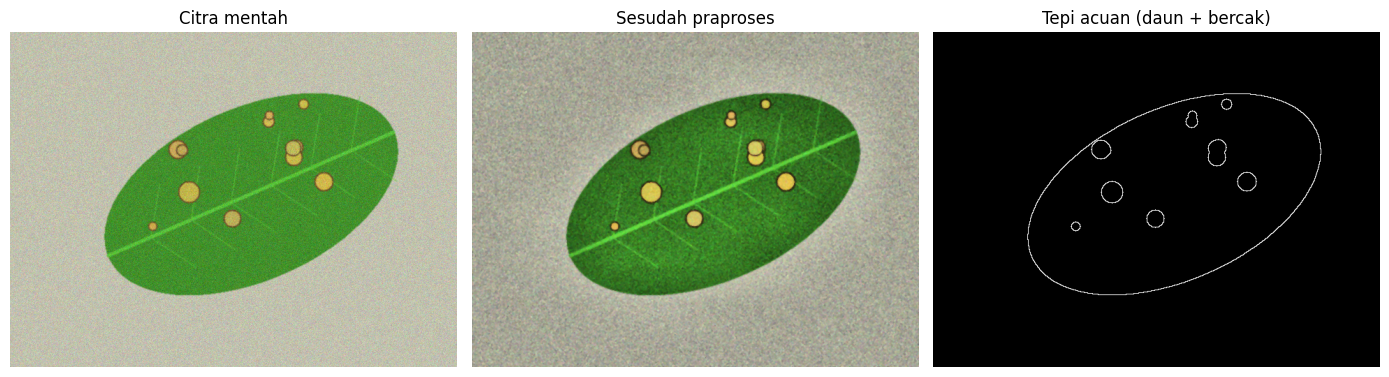

In [13]:
import os, sys, json
# Mengatur direktori kerja aktif ke folder notebook
os.chdir("/content/drive/MyDrive/simuteh-2330511008/notebook")

# Menggunakan path absolut agar modul di folder src selalu terbaca dengan tepat di Colab
sys.path.append("/content/drive/MyDrive/simuteh-2330511008/src")

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

PARAM = json.load(open("../hasil/param_praproses.json"))  # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])

Kode 1.2 Gradien Sobel manual: Gx, Gy, magnitudo, dan arah

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 692.1


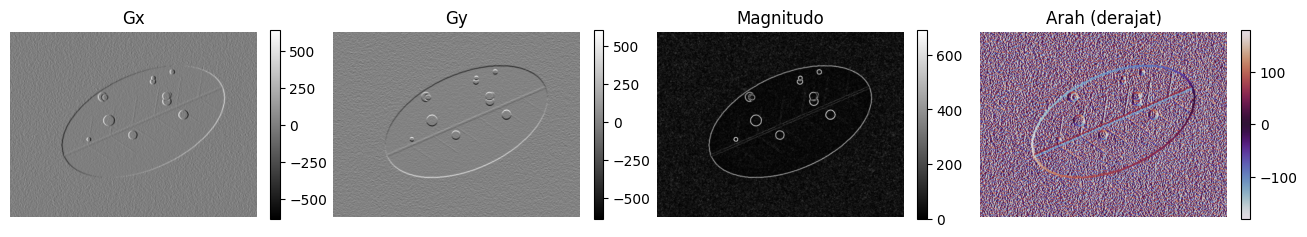

In [14]:
g = pra[:, :, 2].astype(np.float32)          # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx)         # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky)         # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

# bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah,
"Arah (derajat)")]):
    plt.subplot(1, 4, i + 1); plt.imshow(c, cmap="twilight" if i == 3 else
"gray")
    plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)

Kode 1.3 Fungsi Sobel, Prewitt, LoG, dan Canny serta perbandingannya

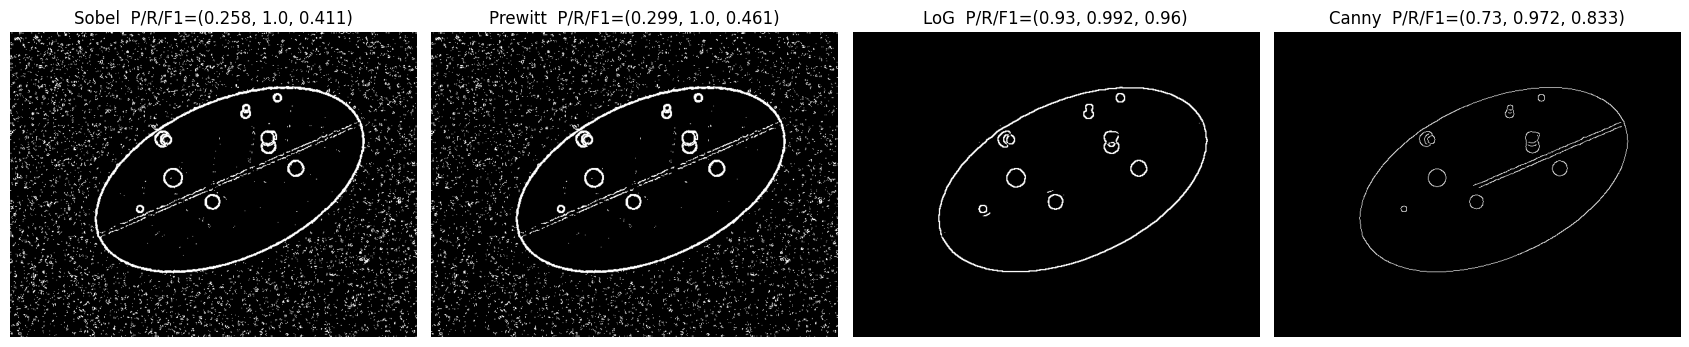

In [15]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma),
cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) *
255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log,
"Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm}  P/R/F1={skor_tepi(e, acuan)}" for nm, e
in hasil.items()],
       ukuran=(17, 3.6))


Kode 1.4 Tabel presisi, recall, dan F1 tepi

In [18]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R", im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])

tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3)
print(ringkas)
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.756  0.751  0.752
                LoG      0.607  0.996  0.748
                Prewitt  0.797  0.957  0.862
                Sobel    0.762  0.965  0.843
          R     Canny    0.985  0.981  0.983
                LoG      0.893  0.997  0.934
                Prewitt  0.545  0.996  0.658
                Sobel    0.481  0.996  0.594
praproses Gray  Canny    0.662  0.947  0.773
                LoG      0.540  0.996  0.691
                Prewitt  0.534  0.996  0.686
                Sobel    0.500  0.996  0.654
          R     Canny    0.958  0.989  0.972
                LoG      0.845  0.997  0.904
                Prewitt  0.474  0.997  0.610
                Sobel    0.426  0.998  0.562


Kode 2.2 Ambang Canny otomatis berbasis median

In [19]:
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah = (1-s) x median, atas = (1+s) x
median."""
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R",
pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis",
skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90",
skor_tepi(tepi_canny(g), ac)[2], np.median(g)])
auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1",
"median"])
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi",
values="F1").round(3))
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))

kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.575  0.549           0.750   0.728   0.809
      tetap 30/90     0.749  0.734           0.901   0.742   0.739
R     otomatis        0.462  0.425           0.713   0.840   0.901
      tetap 30/90     0.987  0.981           0.974   0.966   0.950
kanal  kondisi       
Gray   bayangan          114.6
       gelap             134.4
       kontras_rendah    148.0
       normal            172.9
       terang            193.2
R      bayangan          119.8
       gelap             144.8
       kontras_rendah    149.2
       normal            175.0
       terang            198.4
Name: median, dtype: float64


Kode 2.2 Ambang Canny otomatis berbasis median

In [20]:
# Langkah 2.4: Ambang Canny otomatis berbasis persentil magnitudo gradien
def canny_persentil(g, q, rasio=0.4, sigma=2.0):
    # (1) Haluskan citra dengan Gaussian
    if sigma > 0:
        g_blur = cv2.GaussianBlur(g, (0, 0), sigma)
    else:
        g_blur = g.copy()

    # (2) Hitung magnitudo Sobel
    gx = cv2.Sobel(g_blur.astype(np.float32), cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g_blur.astype(np.float32), cv2.CV_32F, 0, 1, ksize=3)
    mag = np.hypot(gx, gy)

    # (3) Ambang atas = persentil ke-q magnitudo, ambang bawah = rasio x ambang atas
    hi = float(np.percentile(mag, q))
    lo = rasio * hi

    # (4) Panggil cv2.Canny
    return cv2.Canny(g_blur, lo, hi)

# Pengujian q = 90, 95, dan 98 pada kanal Gray dan R di setiap kondisi cahaya
baris_persentil = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra, cv2.COLOR_BGR2GRAY)), ("R", pra[:, :, 2])]:
        for q in [90, 95, 98]:
            e = canny_persentil(g, q=q)
            f1 = skor_tepi(e, ac)[2]
            baris_persentil.append([d.kondisi_cahaya, kanal, f"persentil q={q}", f1])

hasil_persentil = pd.DataFrame(baris_persentil, columns=["kondisi", "kanal", "metode", "F1"])
tabel_persentil = hasil_persentil.pivot_table(index=["kanal", "metode"], columns="kondisi", values="F1").round(3)
print("=== Perbandingan F1 Canny Persentil per Kondisi Cahaya ===")
print(tabel_persentil)

=== Perbandingan F1 Canny Persentil per Kondisi Cahaya ===
kondisi               bayangan  gelap  kontras_rendah  normal  terang
kanal metode                                                         
Gray  persentil q=90     0.064  0.059           0.058   0.061   0.054
      persentil q=95     0.323  0.262           0.183   0.321   0.152
      persentil q=98     0.743  0.755           0.712   0.746   0.739
R     persentil q=90     0.068  0.060           0.058   0.064   0.058
      persentil q=95     0.149  0.103           0.190   0.240   0.114
      persentil q=98     0.976  0.986           0.836   0.983   0.888


Kode 2.3 Tepi palsu di bagian dalam daun sehat

kanal            Gray      R
kondisi                     
bayangan        815.2    0.0
gelap           978.0    0.0
kontras_rendah  176.0    0.0
normal          837.2  172.5
terang          851.5    0.0


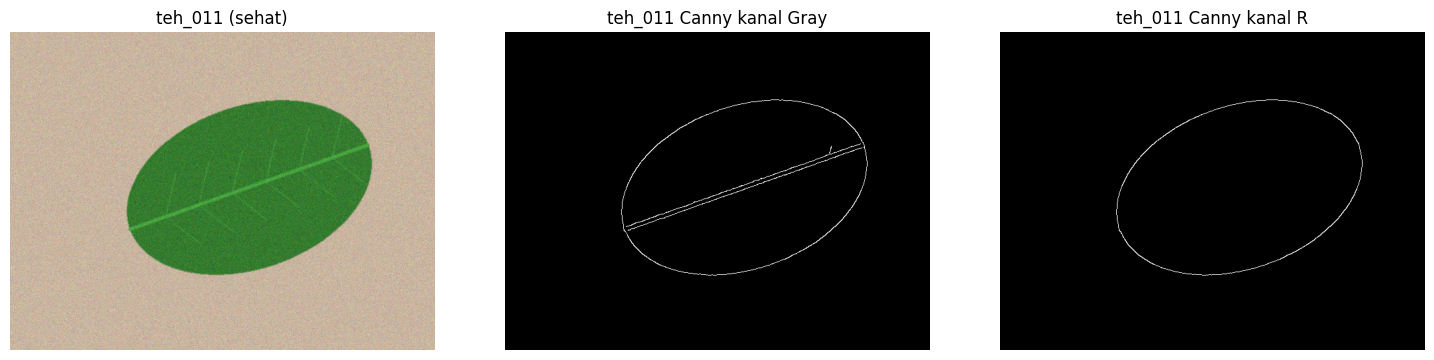

In [21]:
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0     # bagian dalam daun
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R",
pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e); judul.append(f"teh_011 Canny kanal {kanal}")
sehat = pd.DataFrame(baris, columns=["kondisi", "kanal",
"piksel_tepi_di_dalam_daun"])
print(sehat.pivot_table(index="kondisi", columns="kanal",
values="piksel_tepi_di_dalam_daun").round(1))
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul,
ukuran=(15, 3.6))